## Live Deployment Link (Task 1 - Titanic Passenger Survival Prediction System)

**Live demo:** `PASTE-YOUR-LIVE-STREAMLIT-LINK-HERE`

In [1]:
# Step 1: Import Libraries

# Import numerical computing library (used for arrays, math operations, etc.)
import numpy as np

# Import data manipulation library (used for DataFrames, reading/writing data, etc.)
import pandas as pd

# Import pickle (used for saving and loading Python objects/models)
import pickle

# Import train_test_split (used to divide dataset into training and testing sets)
from sklearn.model_selection import train_test_split

# Import LabelEncoder (used to convert categorical values into numeric codes)
from sklearn.preprocessing import LabelEncoder

# Import Support Vector Machine (SVM) model from scikit-learn
from sklearn import svm

# Import evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Import PrettyTable (used to display results in a clean, table format)
from prettytable import PrettyTable

# Import plotting libraries (used for the confusion matrix heatmap)
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Step 2: Load Sample Data

# Read the CSV file and load it into a pandas DataFrame
# 'sample-data.csv' should be present in the working directory
sample_data = pd.read_csv("sample-data.csv")

# Print a header to indicate that sample data is being displayed
print("\n\nSample Data:")
print("============\n")

# Configure pandas to display all rows and columns (so nothing gets hidden with '...')
pd.set_option("display.max_rows", None, "display.max_columns", None)

# Print the complete dataset
print(sample_data)




Sample Data:

    PClass  Gender Sibling     Embarked Survived
0    Third    Male     One  Southampton       No
1   Second  Female    Zero  Southampton      Yes
2    Third    Male    Zero  Southampton       No
3    Third  Female   Three  Southampton      Yes
4    Third    Male    Zero   Queenstown       No
5    First  Female   Three  Southampton      Yes
6    Third    Male    Zero  Southampton       No
7    Third    Male    Zero  Southampton      Yes
8    First    Male    Zero  Southampton       No
9   Second    Male    Zero  Southampton      Yes
10   Third    Male     One   Queenstown       No
11   First    Male    Zero    Cherbourg      Yes
12   First    Male    Zero    Cherbourg       No
13  Second  Female    Zero  Southampton      Yes
14  Second    Male    Zero  Southampton       No
15   Third    Male     One    Cherbourg      Yes
16   Third    Male     Two    Cherbourg       No
17   Third    Male    Zero  Southampton      Yes
18   Third    Male    Zero  Southampton       No
19  

In [3]:
# Step 3.1: Understand Sample Data

# Print a header for clarity
print("\n\nAttributes in Sample Data:")
print("==========================\n")

# Display all column names (attributes) in the dataset
print(sample_data.columns)

# Print a header for instance count
print("\n\nNumber of Instances in Sample Data:", sample_data["PClass"].count())
print("========================================\n")




Attributes in Sample Data:

Index(['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived'], dtype='object')


Number of Instances in Sample Data: 100



In [4]:
# Step 5.1: Train the Label Encoder

# Define label categories for each feature
# These are possible values each column can have in the dataset
pclass = pd.DataFrame({"Pclass": ["First", "Second", "Third"]})
gender = pd.DataFrame({"Gender": ["Male", "Female"]})
sibling = pd.DataFrame({"Sibling": ["Zero", "One", "Two", "Three"]})
embarked = pd.DataFrame({"Embarked": ["Southampton", "Cherbourg", "Queenstown"]})
survived = pd.DataFrame({"Survived": ["Yes", "No"]})

# Create LabelEncoder objects for each categorical column
pclass_label_encoder = LabelEncoder()
gender_label_encoder = LabelEncoder()
sibling_label_encoder = LabelEncoder()
embarked_label_encoder = LabelEncoder()
survived_label_encoder = LabelEncoder()

# Train (fit) the encoders on the given categories
# np.ravel() flattens the DataFrame column into a 1D array for the encoder
pclass_label_encoder.fit(np.ravel(pclass))
gender_label_encoder.fit(np.ravel(gender))
sibling_label_encoder.fit(np.ravel(sibling))
embarked_label_encoder.fit(np.ravel(embarked))
survived_label_encoder.fit(np.ravel(survived))


LabelEncoder()

In [5]:
# Step 5.2: Label Encode the Output

# Create copies of the dataset (one for encoded output, one to keep original)
sample_data_encoded_output = sample_data.copy()
original_sample_data = sample_data.copy()

# Transform "Survived" (categorical -> numeric) using the trained LabelEncoder
print("\n\nSurvived Attribute After Label Encoding:")
print("========================================\n")
sample_data["encoded_survived"] = survived_label_encoder.transform(sample_data['Survived'])

# Show original "Survived" values and their numeric encodings
print(sample_data[["Survived", "encoded_survived"]])

# Replace original categorical columns with encoded values for the output dataset
sample_data_encoded_output[['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived']] = \
    sample_data[['PClass', 'Gender', 'Sibling', 'Embarked', 'encoded_survived']]

# Save the encoded dataset to a CSV file (useful for training/testing later)
sample_data_encoded_output.to_csv(r'sample-data-encoded-output.csv', index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")




Survived Attribute After Label Encoding:

   Survived  encoded_survived
0        No                 0
1       Yes                 1
2        No                 0
3       Yes                 1
4        No                 0
5       Yes                 1
6        No                 0
7       Yes                 1
8        No                 0
9       Yes                 1
10       No                 0
11      Yes                 1
12       No                 0
13      Yes                 1
14       No                 0
15      Yes                 1
16       No                 0
17      Yes                 1
18       No                 0
19      Yes                 1
20       No                 0
21      Yes                 1
22       No                 0
23      Yes                 1
24       No                 0
25      Yes                 1
26       No                 0
27      Yes                 1
28       No                 0
29      Yes                 1
30       No               

In [6]:
# Step 5.3: Label Encode the Input

# Create copies of the dataset (to keep original values safe)
sample_data_encoded = sample_data_encoded_output.copy()

# Encode each input attribute
sample_data_encoded_output["encoded_pclass"] = pclass_label_encoder.transform(sample_data_encoded_output['PClass'])
sample_data_encoded_output["encoded_gender"] = gender_label_encoder.transform(sample_data_encoded_output['Gender'])
sample_data_encoded_output["encoded_sibling"] = sibling_label_encoder.transform(sample_data_encoded_output['Sibling'])
sample_data_encoded_output["encoded_embarked"] = embarked_label_encoder.transform(sample_data_encoded_output['Embarked'])

# Replace categorical columns with encoded values in the dataset
sample_data_encoded[['PClass', 'Gender', 'Sibling', 'Embarked', 'Survived']] = \
    sample_data_encoded_output[['encoded_pclass', 'encoded_gender', 'encoded_sibling', 'encoded_embarked', 'Survived']]

# Print encoded dataset (with numeric values instead of categories)
print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded)

# Save the encoded dataset to a new CSV file
sample_data_encoded.to_csv(r'sample-data-encoded.csv', index=False, header=True)




Sample Data after Label Encoding:

    PClass  Gender  Sibling  Embarked  Survived
0        2       1        0         2         0
1        1       0        3         2         1
2        2       1        3         2         0
3        2       0        1         2         1
4        2       1        3         1         0
5        0       0        1         2         1
6        2       1        3         2         0
7        2       1        3         2         1
8        0       1        3         2         0
9        1       1        3         2         1
10       2       1        0         1         0
11       0       1        3         0         1
12       0       1        3         0         0
13       1       0        3         2         1
14       1       1        3         2         0
15       2       1        0         0         1
16       2       1        2         0         0
17       2       1        3         2         1
18       2       1        3         2         0
19 

In [7]:
# Step 6.1: Splitting Sample Data into Training Data and Testing Data

# Split dataset into training (80%) and testing (20%)
# random_state=0 ensures reproducibility (same split every time)
# shuffle=False keeps the original order of rows (no shuffling before splitting)
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded,
    test_size=0.2,
    random_state=0,
    shuffle=False
)

# Save the training and testing datasets to CSV files
training_data_encoded.to_csv(r'training-data-encoded.csv', index=False, header=True)
testing_data_encoded.to_csv(r'testing-data-encoded.csv', index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)


Training Data shape: (80, 5)
Testing Data shape: (20, 5)


In [8]:
# Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

# Extract input vectors (features) from training data
input_vector_train = training_data_encoded.iloc[:, :-1]

# Extract output labels (target variable) from training data
output_label_train = training_data_encoded.iloc[:, -1]

print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)


Input vectors (train) shape: (80, 4)
Output labels (train) shape: (80,)


In [9]:
# 6.3: Train the Support Vector Classifier

print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")

# Initialize the Support Vector Classifier with chosen parameters
svc_model = svm.SVC(gamma='auto', random_state=0)

# Train the model using the training data (features and labels)
svc_model.fit(input_vector_train, np.ravel(output_label_train))

# Print trained model details (parameters and values)
print(svc_model)




Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


In [10]:
# Step 6.4: Save the Trained Model

# Save the trained SVC model to a file named "svc_trained_model.pkl"
pickle.dump(svc_model, open('svc_trained_model.pkl', 'wb'))
print("Saved: svc_trained_model.pkl")


Saved: svc_trained_model.pkl


In [11]:
# Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]

print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)


Input vectors (test) shape: (20, 4)
Output labels (test) shape: (20,)


In [12]:
# Step 7.2: Load the Saved Model

model = pickle.load(open('svc_trained_model.pkl', 'rb'))
print("Model loaded from svc_trained_model.pkl")


Model loaded from svc_trained_model.pkl


In [13]:
# Step 7.3.1: Make Predictions with the Trained Models on Testing Data

model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv(r'model-predictions.csv', index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by svc_trained_model:")
print("==========================================\n")
print(model_predictions)




Predictions Returned by svc_trained_model:

    PClass  Gender  Sibling  Embarked  Survived  Predictions
80       2       1        2         2         0            0
81       2       0        3         2         1            1
82       2       1        3         2         0            0
83       0       1        0         2         1            0
84       1       1        3         2         0            0
85       2       0        0         1         1            1
86       1       1        3         2         0            0
87       0       0        0         2         1            1
88       2       1        3         2         0            0
89       1       0        3         2         1            1
90       1       1        3         2         0            0
91       1       0        3         2         1            1
92       2       1        3         0         0            0
93       0       1        0         2         1            0
94       0       1        0         2  

In [14]:
# Step 7.4: Calculate the Accuracy Score

model_accuracy_score = accuracy_score(
    model_predictions["Survived"],
    model_predictions["Predictions"]
)

print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))




Accuracy Score:

0.8



Classification Report:



                  precision    recall  f1-score   support

Not Survived (0)       0.71      1.00      0.83        10
    Survived (1)       1.00      0.60      0.75        10

        accuracy                           0.80        20
       macro avg       0.86      0.80      0.79        20
    weighted avg       0.86      0.80      0.79        20


Confusion Matrix:

                      Predicted: Not Survived  Predicted: Survived
Actual: Not Survived                       10                    0
Actual: Survived                            4                    6


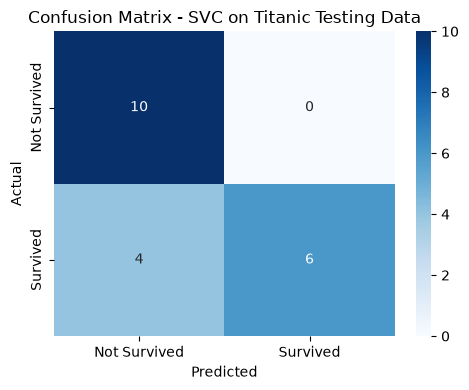

In [15]:
# Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix) (NEW)

print("\nClassification Report:")
print("=======================\n")
print(classification_report(
    model_predictions["Survived"],
    model_predictions["Predictions"],
    target_names=["Not Survived (0)", "Survived (1)"]
))

conf_matrix = confusion_matrix(model_predictions["Survived"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(
    conf_matrix,
    index=["Actual: Not Survived", "Actual: Survived"],
    columns=["Predicted: Not Survived", "Predicted: Survived"]
)
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Not Survived', 'Survived'],
            yticklabels=['Not Survived', 'Survived'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - SVC on Titanic Testing Data')
plt.tight_layout()
plt.show()


In [16]:
# Step 8.1: Take Input from User
# To type your own values, replace the four lines below with:
# pclass_input = input("Please enter PClass here (First, Second, Third): ").strip()
# gender_input = input("Please enter your Gender here (Male, Female): ").strip()
# sibling_input = input("Please enter your Sibling here (Zero, One, Two, Three): ").strip()
# embarked_input = input("Please enter Embarked here (Cherbourg, Southampton, Queenstown): ").strip()

# Demo passenger (edit these values, or swap in input() calls as shown above)
pclass_input = "First"
gender_input = "Male"
sibling_input = "Zero"
embarked_input = "Queenstown"

print(f"PClass: {pclass_input}, Gender: {gender_input}, Sibling: {sibling_input}, Embarked: {embarked_input}")


PClass: First, Gender: Male, Sibling: Zero, Embarked: Queenstown


In [17]:
# Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

user_input = pd.DataFrame({
    'PClass': [pclass_input],
    'Gender': [gender_input],
    'Sibling': [sibling_input],
    'Embarked': [embarked_input]
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)




User Input Feature Vector:

  PClass Gender Sibling    Embarked
0  First   Male    Zero  Queenstown


In [18]:
# Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

unseen_data_features = user_input.copy()

unseen_data_features["PClass"] = pclass_label_encoder.transform(user_input['PClass'])
unseen_data_features["Gender"] = gender_label_encoder.transform(user_input['Gender'])
unseen_data_features["Sibling"] = sibling_label_encoder.transform(user_input['Sibling'])
unseen_data_features["Embarked"] = embarked_label_encoder.transform(user_input['Embarked'])

print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)




User Input Encoded Feature Vector:

   PClass  Gender  Sibling  Embarked
0       0       1        3         1


In [19]:
# Step 8.4: Load the Saved Model

model = pickle.load(open('svc_trained_model.pkl', 'rb'))


In [20]:
# Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

predicted_survival = model.predict(unseen_data_features)

if predicted_survival == 1:
    prediction = "SURVIVED"
if predicted_survival == 0:
    prediction = "NOT SURVIVED"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])

print(pretty_table)


+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|            SURVIVED            |
+--------------------------------+


In [21]:
# Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (History)", "Student Tester", "Student Tester"],
    "Case": [
        "Third class, male, Southampton -> predicted NOT SURVIVED",
        "First class, female -> predicted SURVIVED",
        "Third class, male, large family (3 siblings) -> predicted SURVIVED (unexpected)",
    ],
    "Feedback": [
        "Matches historical record: third-class men had the lowest survival rate.",
        "Matches historical record: women and first-class passengers were prioritized.",
        "Surprising - the model may be picking up a spurious pattern from the small (100-row) sample rather than a real effect. Needs more data to confirm.",
    ],
})
print(example_feedback.to_string(index=False))


               Reviewer                                                                            Case                                                                                                                                           Feedback
Domain Expert (History)                        Third class, male, Southampton -> predicted NOT SURVIVED                                                                           Matches historical record: third-class men had the lowest survival rate.
         Student Tester                                       First class, female -> predicted SURVIVED                                                                      Matches historical record: women and first-class passengers were prioritized.
         Student Tester Third class, male, large family (3 siblings) -> predicted SURVIVED (unexpected) Surprising - the model may be picking up a spurious pattern from the small (100-row) sample rather than a real effect. Needs more data to confi

In [22]:
# Step 9.2: Make a List of Potential Improvements

improvements = [
    "Use the full Titanic dataset (~900 passengers) instead of the 100-row toy sample, so rare combinations (e.g. large families) are better represented",
    "Add Age and Fare as numeric features - both are known strong predictors of survival",
    "Try class-balanced or cross-validated evaluation, since the toy dataset may not be representative",
    "Compare additional models (e.g. Random Forest, Gradient Boosting) beyond SVC/Logistic Regression/Decision Tree",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")


1. Use the full Titanic dataset (~900 passengers) instead of the 100-row toy sample, so rare combinations (e.g. large families) are better represented
2. Add Age and Fare as numeric features - both are known strong predictors of survival
3. Try class-balanced or cross-validated evaluation, since the toy dataset may not be representative
4. Compare additional models (e.g. Random Forest, Gradient Boosting) beyond SVC/Logistic Regression/Decision Tree


In [23]:
# Step 9.3: Improve the Model Based on Feedback

print("Next version: retrain with Age + Fare features on the full dataset, then re-evaluate before replacing svc_trained_model.pkl")


Next version: retrain with Age + Fare features on the full dataset, then re-evaluate before replacing svc_trained_model.pkl
